# Lab 1. SONIC 구조와 Encoder 입력 만들기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kehdgus9434/sonic-vibe-coding-lab/blob/main/notebooks/lab1_sonic_encoder.ipynb)

**주제:** NVIDIA GEAR-SONIC · 사람 걷기 데이터 → 64차원 동작 토큰

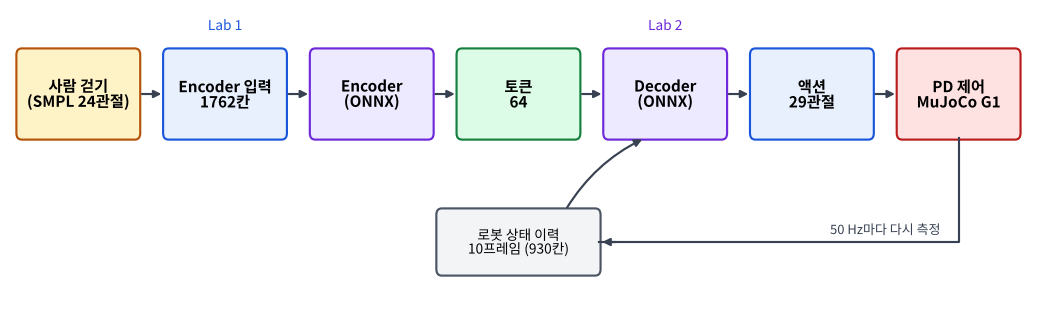

SONIC은 **참조 동작(사람 또는 로봇)을 64차원 토큰으로 압축하는 Encoder**와, **토큰과 로봇 상태로 29개 관절 명령을 만드는 Decoder**로 이루어진 휴머노이드 전신 제어 정책입니다. 이번 Lab에서는 모델의 입출력 '계약'을 읽고, 공식 걷기 샘플로 **Encoder 입력 1762칸을 직접 조립**해 토큰을 만들어 봅니다.

## 오늘의 산출물

1. Encoder/Decoder ONNX 입출력 확인
2. Encoder 입력 1762칸 블록 표
3. 쿼터니언 성분 순서 판정(xyzw vs wxyz)
4. 30 Hz ↔ 50 Hz 시간 정렬
5. Mode-2(SMPL) Encoder 입력 조립과 토큰 시각화

## 실습 방식

- 대부분의 코드는 이미 작성되어 있습니다. **`TODO` 표시가 있는 셀의 빈칸만** 채우면 됩니다.
- `########### Answer #############` 사이의 `None` 또는 `_____`를 알맞은 값·식으로 바꾸세요. 채우지 않고 실행하면 `AssertionError: TODO …` 또는 `NameError: name '_____' is not defined`가 납니다.
- 각 TODO 아래의 `check.…` / `assert`가 바로 ✅/❌로 알려 줍니다. ❌이면 메시지를 읽고 빈칸을 다시 보세요.
- 막히면 AI(ChatGPT·Claude·Gemini, Colab의 Gemini)에게 **그 빈칸 하나**와 [`docs/01_contract.md`](https://github.com/kehdgus9434/sonic-vibe-coding-lab/blob/main/docs/01_contract.md)를 함께 주고 물어봐도 됩니다.
- 마지막의 **해석 질문**은 정답 제출용이 아니라 스스로 정리하기 위한 질문입니다.
- ⚠️ 이 실습의 어떤 출력도 실물 로봇에 보내지 않습니다.

# 0. 환경 설정
아래 셀은 수정하지 않고 실행하면 됩니다. Colab 또는 로컬 Jupyter에서 실행할 수 있습니다. CPU 런타임으로 충분합니다.

In [ ]:
#@title 실습 환경 준비 — 수정하지 말고 실행하세요 (처음 1–2분)
REPO = "https://github.com/kehdgus9434/sonic-vibe-coding-lab"
import os, sys, subprocess
from pathlib import Path
if Path("/content").exists():                              # Google Colab
    LAB_DIR = Path("/content/sonic-vibe-coding-lab")
    if not LAB_DIR.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, str(LAB_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(LAB_DIR / "requirements-colab.txt")], check=True)
else:                                                      # 로컬 Jupyter (저장소 안에서 실행)
    LAB_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(LAB_DIR)
sys.path.insert(0, str(LAB_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
import sonic_lab
from sonic_lab import check, reference as ref, render, analysis
analysis.korean_font()
lab = sonic_lab.start()      # 공식 모델·로봇·걷기 샘플 준비 (lab.policy / lab.sim / lab.motion / lab.contract)

# 1. 목적지 미리보기
완성된 파이프라인으로 사람 걷기 데이터를 넣으면 MuJoCo의 G1이 어떻게 움직이는지 먼저 봅니다. 이 Lab과 Lab 2에서 이 파이프라인의 핵심 부분을 직접 채웁니다.

In [ ]:
summary, arrays = ref.run_physics(lab.sim, lab.policy, lab.motion, mode=2, max_frames=250)
print({k: summary[k] for k in ["simulated_frames", "requested_frames", "completed", "stop_reason"]})
render.show(render.skeleton_video(lab, arrays, "outputs/lab1_preview.mp4", title="SONIC mode 2 (5 s)", seconds=5))

# 2. ONNX 모델 들여다보기
SONIC의 공개 모델은 ONNX 파일 두 개입니다. 입력과 출력의 **크기(차원)** 가 곧 모델과 우리 코드 사이의 약속입니다.

| 모델 | 입력 | 출력 |
|---|---|---|
| Encoder | 참조 동작을 담은 긴 벡터 | 동작 토큰 |
| Decoder | 토큰 + 로봇 상태 이력 | 29개 관절 액션 |

In [ ]:
import onnxruntime as ort
enc = ort.InferenceSession(str(lab.assets.model_dir / "model_encoder.onnx"), providers=["CPUExecutionProvider"])
dec = ort.InferenceSession(str(lab.assets.model_dir / "model_decoder.onnx"), providers=["CPUExecutionProvider"])
for label, session in [("encoder", enc), ("decoder", dec)]:
    i, o = session.get_inputs()[0], session.get_outputs()[0]
    print(f"{label:8s} 입력 {i.name} {i.shape}  →  출력 {o.name} {o.shape}")

# TODO 1: 위 출력에서 각 모델의 입력/출력 '마지막 차원'을 읽어 채우세요.
# Hint:
# - shape는 [batch, 차원] 형태입니다. batch는 1입니다.
#
########### Answer #############
ENC_IN, ENC_OUT = None, None
DEC_IN, DEC_OUT = None, None
########### Answer #############
assert None not in (ENC_IN, ENC_OUT, DEC_IN, DEC_OUT), "TODO 1: 네 값을 모두 채우세요."
check.onnx_io(ENC_IN, ENC_OUT, DEC_IN, DEC_OUT)

### 공식 설정 파일의 주석도 틀릴 수 있다
모델과 함께 배포된 `observation_config.yaml`의 맨 위 주석을 보세요. 위에서 확인한 Decoder 입력 크기와 같나요?

In [ ]:
print("".join((lab.assets.model_dir / "observation_config.yaml").read_text().splitlines(True)[:4]))

# 3. Encoder 입력 1762칸의 구성
Encoder 입력은 14개의 **블록**을 정해진 순서로 이어 붙인 벡터입니다. 블록 이름에 크기가 숨어 있습니다.

| 이름 규칙 | 의미 |
|---|---|
| `10frame` | 현재부터 미래 10프레임 |
| `step1` / `step5` | 프레임 간격 1칸(0.02초) / 5칸(0.1초) |
| `joint_positions` | G1 29관절 (`lowerbody`는 하체 12관절, `wrists`는 손목 6관절) |
| `smpl_joints` | 사람 24관절 × xyz 3 |
| `anchor_orientation` | 회전을 6개 숫자로 표현(6D) |
| `vr_3point` | 머리·양손 3점 (위치 xyz 3 / 방향 쿼터니언 4) |

SONIC은 **모드**에 따라 이 중 일부 블록만 채우고 나머지는 0으로 둡니다. 이번 실습의 사람 걷기는 **모드 2(SMPL)** 입니다.

In [ ]:
import yaml
cfg = yaml.safe_load((lab.assets.model_dir / "observation_config.yaml").read_text())
ENCODER_ORDER = [o["name"] for o in cfg["encoder"]["encoder_observations"] if o.get("enabled", True)]

BLOCK_SIZES = {
    "encoder_mode_4": 4,
    "motion_joint_positions_10frame_step5": 10 * 29,
    "motion_joint_velocities_10frame_step5": 10 * 29,
    "motion_root_z_position_10frame_step5": 10 * 1,
    "motion_root_z_position": 1,
    "motion_anchor_orientation": 6,
    "motion_anchor_orientation_10frame_step5": 10 * 6,
    "motion_joint_positions_lowerbody_10frame_step5": 10 * 12,
    "motion_joint_velocities_lowerbody_10frame_step5": 10 * 12,
    "vr_3point_local_target": 3 * 3,
    "vr_3point_local_orn_target": 3 * 4,
}

# TODO 2: 모드 2(SMPL)가 쓰는 세 블록의 크기를 채우세요.
# Hint:
# - smpl_joints_10frame_step1: 10프레임 × 사람 24관절 × xyz
# - smpl_anchor_orientation_10frame_step1: 10프레임 × 6D 회전
# - motion_joint_positions_wrists_10frame_step1: 10프레임 × 손목 6관절
#
########### Answer #############
BLOCK_SIZES["smpl_joints_10frame_step1"] = None
BLOCK_SIZES["smpl_anchor_orientation_10frame_step1"] = None
BLOCK_SIZES["motion_joint_positions_wrists_10frame_step1"] = None
########### Answer #############
assert None not in BLOCK_SIZES.values(), "TODO 2: 세 블록의 크기를 모두 채우세요."

slices, start = {}, 0
for block in ENCODER_ORDER:
    slices[block] = (start, start + BLOCK_SIZES[block])
    start += BLOCK_SIZES[block]
print("합계:", start)
assert start == ENC_IN, f"TODO 2: 합계 {start} ≠ Encoder 입력 {ENC_IN}"
check.encoder_slices(lab, slices)
display(pd.DataFrame([(k, a, b, b - a) for k, (a, b) in slices.items()], columns=["블록", "시작", "끝", "크기"]))

# 4. 공식 걷기 샘플과 쿼터니언 순서
공식 G1 샘플에는 로봇 루트(골반) 회전이 **두 가지 표현**으로 들어 있습니다.

- `pose_aa[:, 0]`: 축-각(axis-angle) 벡터 — 성분 순서 혼동이 없는 **기준**
- `root_rot`: 쿼터니언 4성분 — `x, y, z, w` 순서일 수도, `w, x, y, z` 순서일 수도 있음

라이브러리마다 순서가 다릅니다(MuJoCo는 `wxyz`, scipy는 `xyzw`). 순서를 잘못 읽어도 **에러는 나지 않습니다.** 그래서 다른 표현과 비교해 데이터로 확인합니다.

In [ ]:
from sonic_lab.reference import load_published_pickle
from sonic_lab.assets import SAMPLE
robot = load_published_pickle(lab.assets.sample_root / "robot_filtered/210531" / SAMPLE)
human = load_published_pickle(lab.assets.sample_root / "smpl_filtered" / SAMPLE)
print("G1  :", {k: np.shape(v) for k, v in robot.items()})
print("SMPL:", {k: np.shape(v) for k, v in human.items()})

In [ ]:
ref_rot = R.from_rotvec(np.asarray(robot["pose_aa"])[:, 0])     # 기준: 축-각 표현
raw = np.asarray(robot["root_rot"])                              # 확인할 쿼터니언

# TODO 3: raw가 [w, x, y, z] 순서라고 가정할 때, scipy가 쓰는 [x, y, z, w] 순서로 바꾸는 열 인덱스를 채우세요.
# Hint:
# - raw[:, [a, b, c, d]]는 열을 a, b, c, d 순서로 다시 배열합니다.
# - [w, x, y, z]에서 x는 1번, w는 0번 열입니다.
#
########### Answer #############
WXYZ_TO_XYZW = None
########### Answer #############
assert WXYZ_TO_XYZW is not None, "TODO 3: 인덱스 리스트를 채우세요."

errors = {}
for order, q in [("xyzw", raw), ("wxyz", raw[:, WXYZ_TO_XYZW])]:
    errors[order] = float(np.degrees((ref_rot.inv() * R.from_quat(q)).magnitude().max()))
print("기준과의 최대 각도 오차(도):", {k: round(v, 3) for k, v in errors.items()})
ROOT_ORDER = min(errors, key=errors.get)
check.root_quat_order(ROOT_ORDER)

# 5. 30 Hz ↔ 50 Hz 시간 정렬
G1 참조는 **30 fps**, 사람(SMPL)은 **50 fps**이고 길이도 조금 다릅니다. SONIC 정책은 **50 Hz**로 동작하므로, 두 데이터가 **모두 존재하는 구간**을 50 Hz 시간축으로 다시 샘플링합니다.

In [ ]:
from scipy.interpolate import interp1d
dur_robot = (len(robot["dof"]) - 1) / float(robot["fps"])
dur_human = (len(human["smpl_joints"]) - 1) / float(human["fps"])
print(f"G1 {len(robot['dof'])}프레임 @ {float(robot['fps']):.0f} fps = {dur_robot:.3f}초")
print(f"사람 {len(human['smpl_joints'])}프레임 @ {float(human['fps']):.0f} fps = {dur_human:.3f}초")

# TODO 4: 두 데이터가 모두 존재하는 구간의 길이(초)를 정하세요.
# Hint:
# - 더 긴 쪽에 맞추면 짧은 데이터의 끝을 넘어 보간하게 됩니다.
#
########### Answer #############
DURATION = None
########### Answer #############
assert DURATION is not None, "TODO 4: DURATION을 채우세요."

times = np.arange(int(np.floor(DURATION * 50 + 1e-8)) + 1) / 50
src_t = np.arange(len(robot["dof"])) / float(robot["fps"])
g1_q50 = interp1d(src_t, np.asarray(robot["dof"]), axis=0)(times)
print("50 Hz 프레임 수:", len(times))
check.resampled_motion(lab, times, g1_q50)

plt.figure(figsize=(10, 2.6))
plt.plot(src_t[:90], np.asarray(robot["dof"])[:90, 3], "o", ms=3, label="30 Hz 원본")
plt.plot(times[:150], g1_q50[:150, 3], "-", lw=1, label="50 Hz 보간")
plt.title("왼쪽 무릎 각도 (rad), 처음 3초"); plt.xlabel("시간 (초)"); plt.legend(); plt.show()

# 6. Mode-2(SMPL) Encoder 입력 조립
이제 앞에서 만든 블록 표대로 Encoder 입력을 채웁니다. `lab.motion`은 50 Hz로 정렬된 공식 샘플입니다.

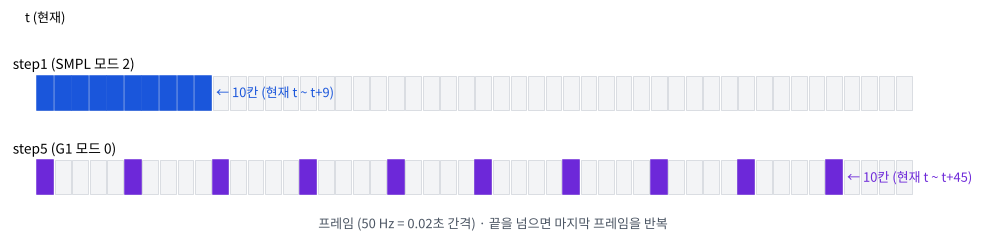

| 블록 | 채울 값 |
|---|---|
| `encoder_mode_4` | `[모드 번호, 0, 0, 0]` |
| `smpl_joints_10frame_step1` | 미래 10프레임의 사람 관절 좌표 (10 × 24 × 3) |
| `smpl_anchor_orientation_10frame_step1` | 각 프레임의 "로봇 기준 사람 루트 회전"을 회전행렬의 **앞 두 열**(3×2=6)로 |
| `motion_joint_positions_wrists_10frame_step1` | 미래 10프레임의 G1 손목 6관절 |

회전행렬 3×3 중 앞 두 열만 있어도 세 번째 열은 외적으로 복원되므로, 6개 숫자로 회전을 표현할 수 있습니다(6D 표현).

In [ ]:
SL = lab.contract.enc_slices          # 블록 이름 → slice (TODO 2에서 만든 표와 같은 것)

def build_encoder_obs_mode2(motion, frame, robot_xyzw, alignment):
    x = np.zeros(1762, np.float32)
    # TODO 5: 현재 프레임부터 미래 9프레임까지 10개의 인덱스 (끝을 넘으면 마지막 프레임 반복)
    # TODO 6: 모드 번호
    # TODO 7: 회전행렬 (10, 3, 3)에서 '앞 두 열'만 고르는 인덱싱
    # Hint:
    # - np.arange(10)은 [0, 1, ..., 9]입니다.
    # - 행렬 M[..., :2]는 모든 행의 앞 두 열, M[..., :2, :]는 앞 두 행입니다.
    #
    ########### Answer #############
    ids = np.minimum(_____, len(motion.times) - 1)
    mode = _____
    rel = R.from_quat(robot_xyzw).inv() * alignment * R.from_quat(motion.human_root_xyzw[ids])
    six_d = rel.as_matrix()[_____]
    ########### Answer #############
    x[SL["encoder_mode_4"]] = [mode, 0, 0, 0]
    x[SL["smpl_joints_10frame_step1"]] = motion.local24[ids].reshape(-1)
    x[SL["smpl_anchor_orientation_10frame_step1"]] = six_d.reshape(-1)
    x[SL["motion_joint_positions_wrists_10frame_step1"]] = motion.wrists_il[ids].reshape(-1)
    return x

check.encoder_obs(lab, build_encoder_obs_mode2)

# 7. 내 Encoder 입력으로 토큰 만들기
방금 만든 입력을 Encoder에 넣어 처음 10초 동안의 토큰을 봅니다(로봇이 참조와 같은 방향을 보고 있다고 가정).

In [ ]:
A = R.identity()
frames = range(0, 500, 2)
tokens = np.array([lab.policy.encode_obs(build_encoder_obs_mode2(lab.motion, t, lab.motion.human_root_xyzw[t], A)) for t in frames])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(lab.motion.times[list(frames)], tokens[:, :8]); axes[0].set(title="토큰 0–7번 차원", xlabel="시간 (초)")
axes[1].imshow(tokens.T, aspect="auto", cmap="coolwarm"); axes[1].set(title="토큰 64차원 전체", xlabel="샘플", ylabel="차원")
plt.tight_layout(); plt.show()
print("토큰 값의 종류(앞 10개):", np.unique(np.round(tokens, 4))[:10])

# 8. Lab 1 정리
```text
공식 걷기 샘플 (사람 50 fps, G1 30 fps)
→ 쿼터니언 순서 확인 (xyzw)
→ 50 Hz 시간 정렬
→ Encoder 입력 1762칸 (모드 2: SMPL 관절 · 6D 방향 · 손목)
→ Encoder → 64차원 토큰
```

## 해석 질문
1. `observation_config.yaml`의 주석(436)과 실제 Decoder 입력(994)이 달랐습니다. 어느 쪽을 믿어야 하고, 왜인가요?
2. 쿼터니언 순서를 잘못 읽었을 때 오차는 몇 도였나요? 에러 메시지 없이 이런 값이 들어가면 무엇이 문제일까요?
3. Encoder 입력에서 모드 2가 쓰지 않는 블록은 0으로 둡니다. 모드 번호를 틀리게 넣으면 어떤 일이 생길까요?
4. 6D 표현에서 '앞 두 열' 대신 '앞 두 행'을 넣으면 TODO 7의 확인이 어떻게 바뀌나요? (직접 바꿔 보세요)
5. 토큰 그래프에서 걸음 주기(약 1초)를 따라 반복되는 패턴이 보이나요? 토큰 값이 연속적이지 않고 계단처럼 보이는 이유는 무엇일까요?